# 01 — Getting started with `esc_etc`

The ESC ETC is an exposure-time calculator for the Lazuli coronagraph. This notebook shows the shortest path from nothing to a signal-to-noise ratio (SNR): build a default `Simulation`, compute SNR, inspect the count-rate contributors, and plot the noise breakdown.

> **Requirements:** this tutorial needs the `config_um` and `config_stp_esc` config repos and an editable install (`pip install -e .`). It uses the **UM 3 m** configuration (the supported path).

In [1]:
import astropy.units as u
import esc_etc
from esc_etc import Simulation, use_lazuli_style, plot_count_rates

use_lazuli_style()   # apply the Lazuli house plotting style globally
print('esc_etc version:', esc_etc.__version__)

esc_etc version: 0.1.0.post0+g311420174.d20260628


## 1. Build a default simulation

`Simulation.from_default(...)` assembles the `Telescope`, `Sensor`, `Scene`, and `Coronagraph` from the UM/ESC configs. The knobs are the host-star magnitude, the planet's delta-magnitude, the raw dark-hole contrast, the post-processing gain, and the planet separation (arcsec).

In [2]:
sim = Simulation.from_default(
    hoststarmag=-0.353, planetdeltamag=20,
    contrast=1e-8, ppgain=10, separation=0.4,
)
sim

## 2. Compute SNR

`get_snr` takes a total integration time and a per-frame time and returns a dict: `snr`, the integrated `signal_e`, the total `noise_e`, and the post-processing noise floor `M`.

In [3]:
out = sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)
print('SNR        :', round(out['snr'], 4))
print('signal [e-]:', round(out['signal_e'], 2))
print('noise  [e-]:', round(out['noise_e'], 2))

assert abs(out['snr'] - 9.5925) < 0.02, out['snr']
print('sanity OK: baseline SNR ~ 9.59')

SNR        : 9.5925
signal [e-]: 3296.97
noise  [e-]: 343.7
sanity OK: baseline SNR ~ 9.59


## 3. Where does the noise come from?

`count_rate_components()` returns the per-second count rates of every contributor (electrons/s).

In [4]:
rates = sim.count_rate_components()
for name in ['source', 'zodi', 'exozodi', 'speckle', 'host']:
    print(f'{name:8s}: {getattr(rates, name):.3e}')

source  : 9.158e-01 electron / s
zodi    : 2.276e-04 electron / s
exozodi : 8.267e-04 electron / s
speckle : 9.158e-01 electron / s
host    : 9.158e+07 electron / s


## 4. Plot the noise-contributor breakdown

`plot_count_rates` is the matplotlib + Lazuli-style breakdown bar chart.

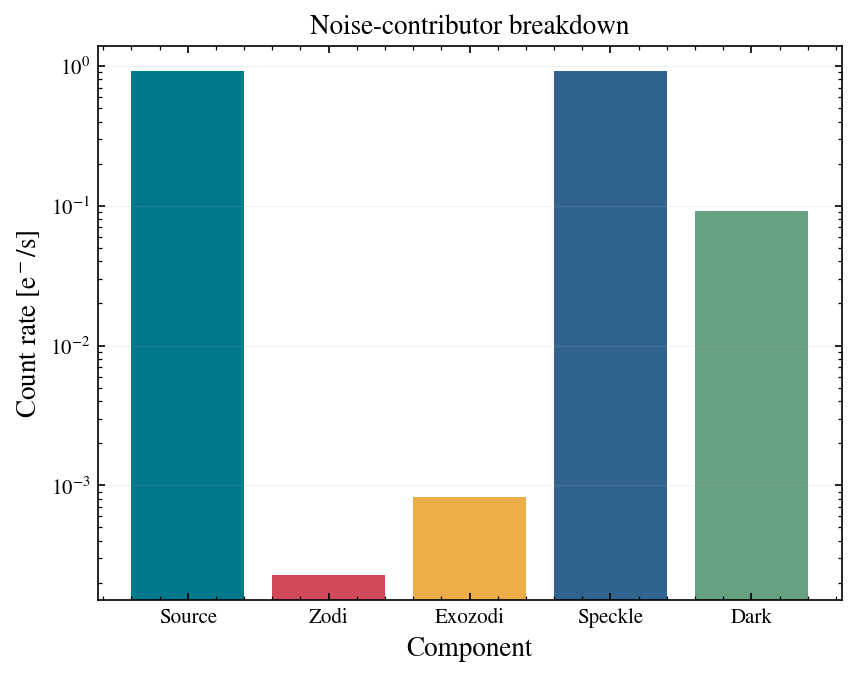

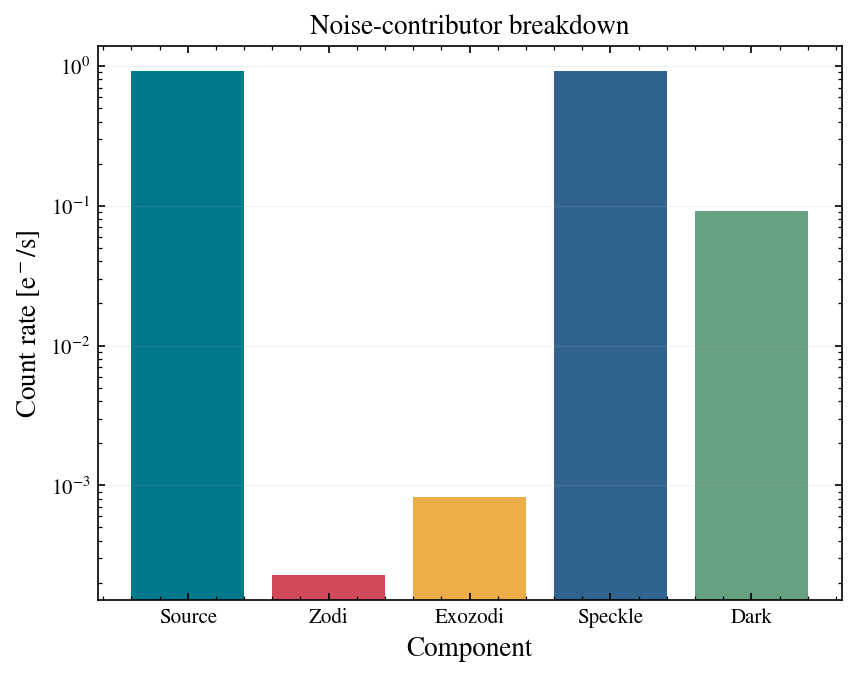

In [5]:
fig, ax = plot_count_rates(sim)
ax.set_title('Noise-contributor breakdown')
fig

## What you learned

- `Simulation.from_default(...)` builds a ready-to-use ETC.
- `get_snr(total_time, frame_time)` returns the SNR and its signal/noise parts.
- `count_rate_components()` + `plot_count_rates` show what dominates the noise.

**Next:** notebook 02 builds the components individually and varies parameters.